In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.mixture import GaussianMixture
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [2]:
data = pd.read_csv("Mall_Customers.csv")

# Select features
X = data[['Annual Income (k$)', 'Spending Score (1-100)']]

# Preprocessing & Scaling
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [3]:
n_components = range(1, 11)
aic = []
bic = []

for n in n_components:
    gmm = GaussianMixture(n_components=n, random_state=42)
    gmm.fit(X_scaled)
    aic.append(gmm.aic(X_scaled))
    bic.append(gmm.bic(X_scaled))


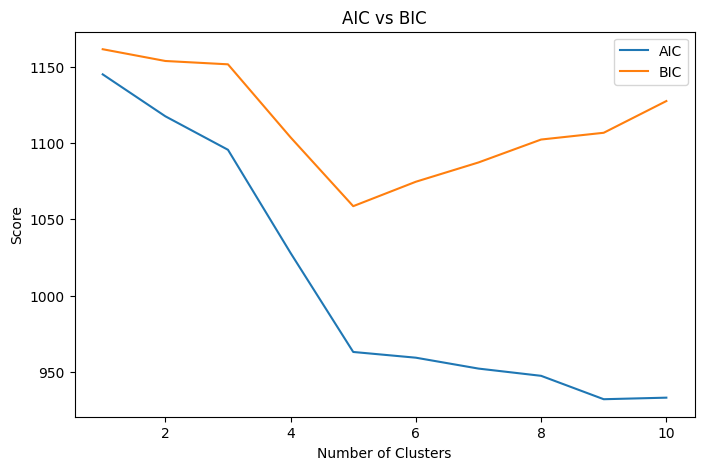

In [4]:
plt.figure(figsize=(8,5))
plt.plot(n_components, aic, label='AIC')
plt.plot(n_components, bic, label='BIC')
plt.xlabel('Number of Clusters')
plt.ylabel('Score')
plt.legend()
plt.title('AIC vs BIC')
plt.show()

In [5]:
optimal_clusters = 5

# Apply GMM (EM algorithm internally used)
gmm = GaussianMixture(n_components=optimal_clusters, random_state=42)
gmm.fit(X_scaled)

# Predict cluster probabilities
probabilities = gmm.predict_proba(X_scaled)

In [6]:
#  Assign clusters (highest probability)
gmm_labels = np.argmax(probabilities, axis=1)

# Add to dataset
data['GMM_Cluster'] = gmm_labels

#  K-Means for comparison
kmeans = KMeans(n_clusters=optimal_clusters, random_state=42)
kmeans_labels = kmeans.fit_predict(X_scaled)
data['KMeans_Cluster'] = kmeans_labels


In [7]:
# Evaluation Metrics
print("\n--- Evaluation Metrics ---")

# Log-Likelihood
print("Log-Likelihood:", gmm.score(X_scaled))

# AIC & BIC
print("AIC:", gmm.aic(X_scaled))
print("BIC:", gmm.bic(X_scaled))


--- Evaluation Metrics ---
Log-Likelihood: -2.262502621973241
AIC: 963.0010487892964
BIC: 1058.6522524191894


In [8]:
# Silhouette Score
print("Silhouette Score (GMM):", silhouette_score(X_scaled, gmm_labels))
print("Silhouette Score (KMeans):", silhouette_score(X_scaled, kmeans_labels))


Silhouette Score (GMM): 0.5536892843811245
Silhouette Score (KMeans): 0.5546571631111091


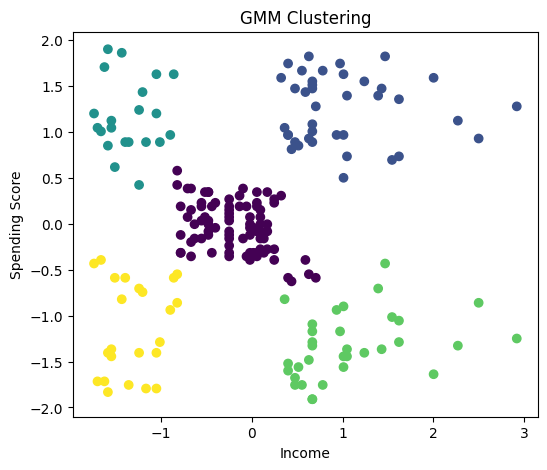

In [9]:
# GMM Clusters
plt.figure(figsize=(6,5))
plt.scatter(X_scaled[:,0], X_scaled[:,1], c=gmm_labels, cmap='viridis')
plt.title("GMM Clustering")
plt.xlabel("Income")
plt.ylabel("Spending Score")
plt.show()

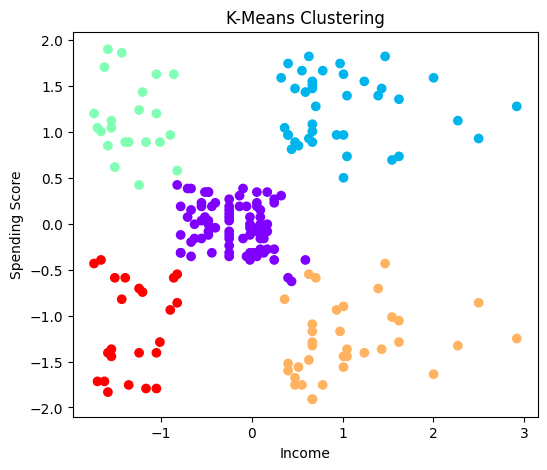

In [10]:
# K-Means Clusters
plt.figure(figsize=(6,5))
plt.scatter(X_scaled[:,0], X_scaled[:,1], c=kmeans_labels, cmap='rainbow')
plt.title("K-Means Clustering")
plt.xlabel("Income")
plt.ylabel("Spending Score")
plt.show()

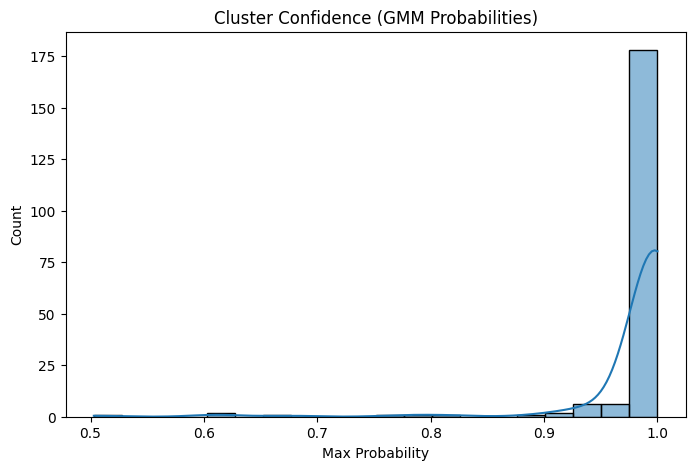

In [11]:
# Probability Distribution (Soft Clustering)
plt.figure(figsize=(8,5))
sns.histplot(probabilities.max(axis=1), bins=20, kde=True)
plt.title("Cluster Confidence (GMM Probabilities)")
plt.xlabel("Max Probability")
plt.show()